# Task 1: PDF Processing and Summarisation

Identify the assigned report, extract and clean its text, preserve document
sections and create token-aware chunks with source-page references.

In [1]:
%pip -q install pymupdf pytesseract pillow transformers accelerate \
    bitsandbytes jsonschema pandas sentencepiece

import re
import json
import hashlib
import random
import shutil
import subprocess
import gc

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import pymupdf
import pytesseract

from PIL import Image
from transformers import AutoTokenizer
from jsonschema import Draft202012Validator

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path.cwd()
PDF_PATH = ROOT / "columbia_2023.pdf"

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
PIPELINE_VERSION = "article_iv_v1"

OUTPUT_DIR = ROOT / "outputs_article_iv"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHUNK_TOKENS = 450
OVERLAP_TOKENS = 50

def stable_hash(value):
    text = json.dumps(
        value, sort_keys=True, ensure_ascii=False, default=str
    )
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")

    temporary.write_text(
        json.dumps(
            value, ensure_ascii=False, indent=2, allow_nan=False
        ),
        encoding="utf-8",
    )
    temporary.replace(path)

def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def normalise(text):
    return re.sub(r"\s+", " ", text).strip()

def word_count(text):
    return len(re.findall(r"\b[\w’-]+\b", text))

print("PDF:", PDF_PATH.name)
print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "Unavailable")

PDF: columbia_2023.pdf
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


## 1.1 Source Verification

Check the country, report type and report number before processing. Use the
document hash to keep this report's cached outputs separate from earlier files.

In [2]:
if not PDF_PATH.is_file():
    raise FileNotFoundError(
        f"Place {PDF_PATH.name} in the Colab working folder: {ROOT}"
    )

PDF_HASH = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()
RUN_CACHE = ROOT / "cache" / PDF_HASH[:16] / PIPELINE_VERSION
RUN_CACHE.mkdir(parents=True, exist_ok=True)

with pymupdf.open(PDF_PATH) as document:
    if document.needs_pass:
        raise ValueError("The PDF is password protected.")

    if document.page_count == 0:
        raise ValueError("The PDF contains no pages.")

    cover = normalise(document[0].get_text())
    title = document.metadata.get("title") or ""

    country_confirmed = bool(
        re.search(r"\bCOLOMBIA\b", cover, re.IGNORECASE)
    )
    article_iv_confirmed = bool(
        re.search(
            r"2023\s+ARTICLE\s+IV\s+CONSULTATION",
            cover,
            re.IGNORECASE,
        )
    )
    report_match = re.search(
        r"Country Report No\.\s*(\d+/\d+)",
        cover,
        re.IGNORECASE,
    )

    document_info = {
        "filename": PDF_PATH.name,
        "sha256": PDF_HASH,
        "page_count": len(document),
        "metadata_title": title,
        "cover_text": cover,
        "country_confirmed": country_confirmed,
        "article_iv_confirmed": article_iv_confirmed,
        "report_type": (
            "2023 Article IV Consultation"
            if article_iv_confirmed else "Not confirmed"
        ),
        "report_number": (
            report_match.group(1) if report_match else None
        ),
    }

if not country_confirmed or not article_iv_confirmed:
    raise ValueError(
        "This file is not confirmed as Colombia's 2023 Article IV report. "
        "Check that the correct PDF replaced the old file."
    )

save_json(OUTPUT_DIR / "document_info.json", document_info)

print("Country: Colombia")
print("Report:", document_info["report_type"])
print("Report number:", document_info["report_number"])
print("Pages:", document_info["page_count"])
print("Document cache:", RUN_CACHE.parent.name)

Country: Colombia
Report: 2023 Article IV Consultation
Report number: 23/120
Pages: 80
Document cache: 95521a05d87269ea


## 1.2 Text Extraction and OCR

Retain the native text for verification. Remove repeated margins from a cleaned
copy and apply OCR when meaningful native text is sparse. OCR results remain
subject to image checks, particularly for charts and numerical tables.

In [3]:
def ensure_tesseract():
    if shutil.which("tesseract"):
        return

    if not shutil.which("apt-get"):
        raise RuntimeError("Tesseract is required for scanned pages.")

    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True,
        stdout=subprocess.DEVNULL,
    )
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "tesseract-ocr"],
        check=True,
        stdout=subprocess.DEVNULL,
    )

def clean_layout(text, repeated):
    lines = (
        text.replace("\x00", "")
        .replace("\u00ad", "")
        .replace("\u00a0", " ")
        .splitlines()
    )
    nonempty = [i for i, line in enumerate(lines) if line.strip()]
    margins = set(nonempty[:3] + nonempty[-4:])
    retained = []

    for index, line in enumerate(lines):
        stripped = normalise(line)

        if "Not for Redistribution" in stripped:
            continue

        if index in margins:
            if stripped in repeated:
                continue
            if re.fullmatch(r"\d+", stripped):
                continue
            if re.fullmatch(
                r"(?:\d+\s+)?INTERNATIONAL MONETARY FUND(?:\s+\d+)?",
                stripped,
            ):
                continue

        retained.append(
            re.sub(r"[ \t]+", " ", line).strip()
        )

    return re.sub(
        r"\n{3,}", "\n\n", "\n".join(retained)
    ).strip()

def extract_clean_pages():
    records = []

    with pymupdf.open(PDF_PATH) as document:
        native_pages = [
            page.get_text("text", sort=True)
            for page in document
        ]

        margin_counts = Counter()

        for text in native_pages:
            lines = [
                normalise(line)
                for line in text.splitlines() if line.strip()
            ]

            margin_counts.update(set(
                line for line in lines[:2] + lines[-3:]
                if 3 <= len(line) <= 100
            ))

        repeated = {
            line for line, count in margin_counts.items()
            if count >= max(5, int(len(document) * 0.20))
        }

        for index, page in enumerate(document):
            native = native_pages[index]
            native_clean = clean_layout(native, repeated)

            selected = native_clean
            ocr_text = ""
            method = "native"
            warnings = []

            meaningful = len(re.sub(
                r"[^A-Za-z0-9]", "", native_clean
            ))

            if meaningful < 250:
                ensure_tesseract()
                pixmap = page.get_pixmap(dpi=300, alpha=False)
                image = Image.frombytes(
                    "RGB",
                    (pixmap.width, pixmap.height),
                    pixmap.samples,
                )

                ocr_text = pytesseract.image_to_string(
                    image, config="--psm 3"
                )
                ocr_clean = clean_layout(ocr_text, repeated)

                if len(ocr_clean) > len(native_clean):
                    selected = ocr_clean
                    method = "ocr"
                else:
                    method = "native; OCR attempted"

                warnings.append("Image/OCR verification required.")

            prose = re.sub(
                r"([A-Za-z])-\n\s*([a-z])",
                r"\1\2",
                selected,
            )
            prose = "\n\n".join(
                normalise(block)
                for block in re.split(r"\n\s*\n", prose)
                if block.strip()
            )

            if len(prose) < 80:
                warnings.append("Little readable text remains.")

            records.append({
                "pdf_page": index + 1,
                "raw_text": native,
                "ocr_text": ocr_text,
                "layout_text": selected,
                "text": prose,
                "method": method,
                "character_count": len(prose),
                "warnings": warnings,
            })

    return records

page_cache = RUN_CACHE / "cleaned_pages.json"

if page_cache.exists():
    pages = load_json(page_cache)
else:
    pages = extract_clean_pages()
    save_json(page_cache, pages)

save_json(OUTPUT_DIR / "cleaned_pages.json", pages)

page_quality = pd.DataFrame([
    {
        "PDF page": page["pdf_page"],
        "Method": page["method"],
        "Characters": page["character_count"],
        "Warnings": "; ".join(page["warnings"]),
    }
    for page in pages
])

display(page_quality)

print("Pages processed:", len(pages))
print("OCR attempted on:", [
    page["pdf_page"]
    for page in pages
    if page["method"] != "native"
])

,PDF page,Method,Characters,Warnings
0,1,native,1720,
1,2,native,2580,
2,3,native,3420,
3,4,native,4047,
4,5,native,2408,
...,...,...,...,...
75,76,native,3281,
76,77,native,3387,
77,78,native,3467,
78,79,native,3315,


Pages processed: 80
OCR attempted on: [23, 26, 29, 30, 31, 60, 68]


## 1.3 Section Boundaries and Contextual Chunks

Separate front matter, narrative sections and standalone exhibits. Keep annex
figures and tables within their parent annex. Preserve section titles, exhibit
headings and PDF page references in the chunk records.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

def token_ids(text):
    return tokenizer.encode(
        text, add_special_tokens=False, verbose=False
    )

def token_count(text):
    return len(token_ids(text))

main_headings = {
    "KEY ISSUES",
    "BACKGROUND",
    "RECENT DEVELOPMENTS",
    "OUTLOOK AND RISKS",
    "POLICY DISCUSSIONS",
    "STAFF APPRAISAL",
    "FUND RELATIONS",
    "STATISTICAL ISSUES",
}

sections = []
current = None
annex_active = False
statement_active = False

def add_section(title, kind):
    section = {
        "section_id": f"s{len(sections) + 1:03d}",
        "title": title,
        "kind": kind,
        "blocks": [],
    }
    sections.append(section)
    return section

for page in pages:
    layout = page["layout_text"]
    lines = layout.splitlines()
    visible = [normalise(line) for line in lines if line.strip()]
    top = visible[:16]

    # Exclude cover, administrative pages and contents continuations.
    if re.search(
        r"following documents have been released|"
        r"Copies of this report are available",
        layout, re.IGNORECASE,
    ):
        continue

    if (
        "CONTENTS" in top
        or len(re.findall(r"_{5,}", layout)) >= 4
    ):
        current = None
        continue

    if re.search(r"^\s*Approved By", layout, re.MULTILINE):
        if "CONTENTS" in layout:
            current = None
            continue

    press_release = any(
        re.match(r"PR\s*\d+/\d+", line) for line in top
    )

    statement_title = next((
        line for line in top
        if re.match(
            r"^Statement by\s+[A-Z][a-z]+\s+[A-Z][a-z]+",
            line,
        )
    ), None)

    annex_title = next((
        line for line in top
        if re.match(r"^Annex\s+[IVX]+\.", line, re.IGNORECASE)
    ), None)

    exhibit_title = next((
        line for line in top
        if re.match(
            r"^(?:Table|Figure)\s+\d+[a-z]?[.:]\s*Colombia",
            line, re.IGNORECASE,
        )
    ), None)

    if statement_title:
        current = add_section(
            "Executive Director Statement", "statement"
        )
        statement_active = True
        annex_active = False

    elif annex_title:
        current = add_section(annex_title, "annex")
        annex_active = True
        statement_active = False

    elif press_release:
        current = add_section("Press Release", "narrative")
        annex_active = False
        statement_active = False

    elif exhibit_title and not annex_active and not statement_active:
        current = add_section(exhibit_title, "exhibit")

    buffer = []

    def flush_buffer():
        if current is not None and buffer:
            text = "\n".join(buffer).strip()
            if text:
                current["blocks"].append({
                    "page": page["pdf_page"],
                    "text": text,
                })
        buffer.clear()

    index = 0

    while index < len(lines):
        text = normalise(lines[index])
        heading = None

        if not statement_active and not annex_active:
            if text.upper() in main_headings:
                heading = text.title()

            elif re.match(r"^[A-D]\.\s+[A-Z]", text):
                heading = text

                # This report wraps the final policy-subsection title.
                following = index + 1
                while following < len(lines) and not lines[following].strip():
                    following += 1

                if (
                    following < len(lines)
                    and normalise(lines[following]) == "Economy"
                    and "Greener" in text
                ):
                    heading += " Economy"
                    index = following

            elif text.upper() == (
                "RELATIONS WITH OTHER INTERNATIONAL FINANCIAL"
            ):
                heading = (
                    "Relations with Other International Financial Institutions"
                )
                following = index + 1
                while following < len(lines) and not lines[following].strip():
                    following += 1
                if (
                    following < len(lines)
                    and normalise(lines[following]).upper() == "INSTITUTIONS"
                ):
                    index = following

            elif text.startswith("Executive Board Assessment"):
                heading = "Executive Board Assessment"

        # Start the informational annex after the analytical annexes.
        if (
            not statement_active
            and text.upper() == "FUND RELATIONS"
        ):
            annex_active = False
            heading = "Fund Relations"

        if heading:
            flush_buffer()
            current = add_section(heading, "narrative")
        else:
            buffer.append(lines[index])

        index += 1

    flush_buffer()

sections = [
    section for section in sections
    if any(block["text"].strip() for block in section["blocks"])
]

if not sections:
    raise ValueError("No usable sections were detected.")

chunks = []

for section in sections:
    ids = []
    source_pages = []

    for block in section["blocks"]:
        block_ids = token_ids(block["text"] + "\n\n")
        ids.extend(block_ids)
        source_pages.extend([block["page"]] * len(block_ids))

    prefix = token_ids(section["title"] + "\n")[:65]
    capacity = CHUNK_TOKENS - len(prefix)
    step = capacity - OVERLAP_TOKENS

    if step <= 0:
        raise ValueError("Chunk settings leave no room for source text.")

    start = 0

    while start < len(ids):
        end = min(start + capacity, len(ids))
        combined = prefix + ids[start:end]

        chunks.append({
            "chunk_id": f"c{len(chunks) + 1:05d}",
            "section_id": section["section_id"],
            "section": section["title"],
            "kind": section["kind"],
            "pages": sorted(set(source_pages[start:end])),
            "text": tokenizer.decode(combined),
            "token_count": len(combined),
        })

        if end == len(ids):
            break
        start += step

chunk_lookup = {
    chunk["chunk_id"]: chunk for chunk in chunks
}

save_json(OUTPUT_DIR / "sections.json", sections)
save_json(OUTPUT_DIR / "chunks.json", chunks)

section_overview = pd.DataFrame([
    {
        "Section": section["title"],
        "Type": section["kind"],
        "Start PDF page": min(
            block["page"] for block in section["blocks"]
        ),
        "End PDF page": max(
            block["page"] for block in section["blocks"]
        ),
        "Chunks": sum(
            chunk["section_id"] == section["section_id"]
            for chunk in chunks
        ),
    }
    for section in sections
])

display(section_overview)

print("Total chunks:", len(chunks))
print("Maximum tokens:", max(c["token_count"] for c in chunks))
print("Source report:", document_info["report_number"])

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

,Section,Type,Start PDF page,End PDF page,Chunks
0,Press Release,narrative,2,2,2
1,Executive Board Assessment,narrative,3,3,2
2,Table 1. Colombia: Selected Economic and Finan...,exhibit,4,5,6
3,Key Issues,narrative,5,6,2
4,Background,narrative,9,9,1
5,Recent Developments,narrative,9,13,8
6,Outlook And Risks,narrative,13,14,2
7,Policy Discussions,narrative,14,14,1
8,A. Fiscal Policy: Tighter for Longer,narrative,14,17,5
9,B. Monetary and Exchange Rate Policies: Keepin...,narrative,17,18,2


Total chunks: 180
Maximum tokens: 450
Source report: 23/120


## 1.4 Language Model and Cached Generation

Load Qwen in 4-bit mode and reuse saved responses for identical requests.
Validate structured outputs and retain failed responses for inspection.

In [5]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

if not torch.cuda.is_available():
    raise RuntimeError(
        "Enable a GPU: Runtime → Change runtime type → T4 GPU."
    )

if globals().get("loaded_model_id") != MODEL_ID:
    if "model" in globals():
        del model
        gc.collect()
        torch.cuda.empty_cache()

    quantization = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
    )

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        quantization_config=quantization,
        device_map="auto",
        dtype=torch.float16,
    )
    loaded_model_id = MODEL_ID

model.eval()

LLM_CACHE = RUN_CACHE / "llm"
LLM_CACHE.mkdir(parents=True, exist_ok=True)

def generate_text(system, user, max_new_tokens=400):
    request = {
        "model": MODEL_ID,
        "version": PIPELINE_VERSION + "_generation_v2",
        "system": system,
        "user": user,
        "max_new_tokens": max_new_tokens,
        "do_sample": False,
    }

    cache_path = LLM_CACHE / f"{stable_hash(request)}.json"

    if cache_path.exists():
        return load_json(cache_path)["text"]

    prompt = tokenizer.apply_chat_template(
        [
            {"role": "system", "content": system},
            {"role": "user", "content": user},
        ],
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
    ).to(model.get_input_embeddings().weight.device)

    input_length = inputs["input_ids"].shape[1]
    context_limit = min(
        int(model.config.max_position_embeddings), 8192
    )

    if input_length + max_new_tokens > context_limit:
        raise ValueError(
            f"Request needs {input_length + max_new_tokens} tokens; "
            f"configured limit is {context_limit}."
        )

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            do_sample=False,
            max_new_tokens=max_new_tokens,
            pad_token_id=tokenizer.eos_token_id,
        )

    response = tokenizer.decode(
        generated[0, input_length:],
        skip_special_tokens=True,
    ).strip()

    if not response:
        raise ValueError("The model returned an empty response.")

    save_json(cache_path, {
        "request": request,
        "text": response,
    })

    return response


def parse_json_response(text):
    cleaned = re.sub(
        r"```(?:json)?", "", text, flags=re.IGNORECASE
    ).strip()

    try:
        return json.loads(cleaned)
    except json.JSONDecodeError:
        decoder = json.JSONDecoder()

        for match in re.finditer(r"[\{\[]", cleaned):
            try:
                result, _ = decoder.raw_decode(
                    cleaned[match.start():]
                )
                return result
            except json.JSONDecodeError:
                continue

    raise ValueError("No valid JSON object or array was found.")


def generate_json(
    system,
    user,
    schema,
    fallback,
    max_new_tokens=500,
    max_attempts=3,
):
    Draft202012Validator.check_schema(schema)
    validator = Draft202012Validator(schema)

    errors = []
    last_response = ""

    for attempt in range(1, max_attempts + 1):
        prompt = (
            user
            + "\nReturn only JSON matching this schema:\n"
            + json.dumps(schema)
        )

        if errors:
            prompt += (
                "\nThe previous response failed validation:\n"
                + errors[-1][:300]
                + "\nCorrect the structure without inventing information."
            )

        try:
            last_response = generate_text(
                system, prompt, max_new_tokens
            )
            data = parse_json_response(last_response)
            validator.validate(data)

            return {
                "data": data,
                "status": "schema_valid",
                "attempts": attempt,
                "errors": errors,
                "raw_response": last_response,
            }

        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            errors.append("GPU memory exhausted.")
            break

        except Exception as exc:
            errors.append(str(exc)[:500])

    return {
        "data": json.loads(json.dumps(fallback)),
        "status": "fallback",
        "attempts": len(errors),
        "errors": errors,
        "raw_response": last_response,
    }


print("Loaded:", MODEL_ID)
print("Quantization: 4-bit NF4")
print(generate_text(
    "Follow instructions precisely.",
    "Reply with READY.",
    max_new_tokens=12,
))

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded: Qwen/Qwen2.5-3B-Instruct
Quantization: 4-bit NF4
READY


## 1.5 Preliminary Source Checks

Test the model on a short narrative passage. Check summary length and retain
the original response. Validate a numerical example against its source quote
and reporting period before running the full task.

In [6]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

if not torch.cuda.is_available():
    raise RuntimeError(
        "Enable a GPU: Runtime → Change runtime type → T4 GPU."
    )

if globals().get("loaded_model_id") != MODEL_ID:
    if "model" in globals():
        del model
        gc.collect()
        torch.cuda.empty_cache()

    quantization = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
    )

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        quantization_config=quantization,
        device_map="auto",
        dtype=torch.float16,
    )
    loaded_model_id = MODEL_ID

model.eval()

LLM_CACHE = RUN_CACHE / "llm"
LLM_CACHE.mkdir(parents=True, exist_ok=True)

def generate_text(system, user, max_new_tokens=400):
    request = {
        "model": MODEL_ID,
        "version": PIPELINE_VERSION + "_generation_v2",
        "system": system,
        "user": user,
        "max_new_tokens": max_new_tokens,
        "do_sample": False,
    }

    cache_path = LLM_CACHE / f"{stable_hash(request)}.json"

    if cache_path.exists():
        return load_json(cache_path)["text"]

    prompt = tokenizer.apply_chat_template(
        [
            {"role": "system", "content": system},
            {"role": "user", "content": user},
        ],
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
    ).to(model.get_input_embeddings().weight.device)

    input_length = inputs["input_ids"].shape[1]
    context_limit = min(
        int(model.config.max_position_embeddings), 8192
    )

    if input_length + max_new_tokens > context_limit:
        raise ValueError(
            f"Request needs {input_length + max_new_tokens} tokens; "
            f"configured limit is {context_limit}."
        )

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            do_sample=False,
            max_new_tokens=max_new_tokens,
            pad_token_id=tokenizer.eos_token_id,
        )

    response = tokenizer.decode(
        generated[0, input_length:],
        skip_special_tokens=True,
    ).strip()

    if not response:
        raise ValueError("The model returned an empty response.")

    save_json(cache_path, {
        "request": request,
        "text": response,
    })

    return response


def parse_json_response(text):
    cleaned = re.sub(
        r"```(?:json)?", "", text, flags=re.IGNORECASE
    ).strip()

    try:
        return json.loads(cleaned)
    except json.JSONDecodeError:
        decoder = json.JSONDecoder()

        for match in re.finditer(r"[\{\[]", cleaned):
            try:
                result, _ = decoder.raw_decode(
                    cleaned[match.start():]
                )
                return result
            except json.JSONDecodeError:
                continue

    raise ValueError("No valid JSON object or array was found.")


def generate_json(
    system,
    user,
    schema,
    fallback,
    max_new_tokens=500,
    max_attempts=3,
):
    Draft202012Validator.check_schema(schema)
    validator = Draft202012Validator(schema)

    errors = []
    last_response = ""

    for attempt in range(1, max_attempts + 1):
        prompt = (
            user
            + "\nReturn only JSON matching this schema:\n"
            + json.dumps(schema)
        )

        if errors:
            prompt += (
                "\nThe previous response failed validation:\n"
                + errors[-1][:300]
                + "\nCorrect the structure without inventing information."
            )

        try:
            last_response = generate_text(
                system, prompt, max_new_tokens
            )
            data = parse_json_response(last_response)
            validator.validate(data)

            return {
                "data": data,
                "status": "schema_valid",
                "attempts": attempt,
                "errors": errors,
                "raw_response": last_response,
            }

        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            errors.append("GPU memory exhausted.")
            break

        except Exception as exc:
            errors.append(str(exc)[:500])

    return {
        "data": json.loads(json.dumps(fallback)),
        "status": "fallback",
        "attempts": len(errors),
        "errors": errors,
        "raw_response": last_response,
    }


print("Loaded:", MODEL_ID)
print("Quantization: 4-bit NF4")
print(generate_text(
    "Follow instructions precisely.",
    "Reply with READY.",
    max_new_tokens=12,
))

Loaded: Qwen/Qwen2.5-3B-Instruct
Quantization: 4-bit NF4
READY


## 1.5 Preliminary Source Checks

Test the model on a short narrative passage. Check summary length and retain
the original response. Validate a numerical example against its source quote
and reporting period before running the full task.

In [7]:
def summarise_source(source, instruction=""):
    errors = []
    response = ""

    try:
        response = generate_text(
            (
                "Summarise only the supplied evidence. Preserve dates, "
                "uncertainty and the difference between observations and "
                "forecasts. Do not invent causal relationships."
            ),
            (
                instruction
                + "\nWrite one factual paragraph of 50–85 words. "
                "Return only the paragraph, without a heading.\n\n"
                "SOURCE:\n" + source
            ),
            max_new_tokens=350,
        )

        # Shorten an overlength response rather than discarding it immediately.
        for target in [75, 60]:
            if word_count(response) < 100:
                break

            response = generate_text(
                "Shorten the supplied text without adding facts.",
                (
                    f"Rewrite this as one paragraph of no more than "
                    f"{target} words. Return only the paragraph.\n\n"
                    + response
                ),
                max_new_tokens=230,
            )

        count = word_count(response)

        if not 10 <= count < 100:
            errors.append(
                f"Summary length check failed: {count} words."
            )
            return {
                "summary": "",
                "status": "fallback",
                "word_count": count,
                "raw_response": response,
                "errors": errors,
            }

        return {
            "summary": response,
            "status": "generated",
            "word_count": count,
            "raw_response": response,
            "errors": errors,
        }

    except Exception as exc:
        return {
            "summary": "",
            "status": "fallback",
            "word_count": 0,
            "raw_response": response,
            "errors": [str(exc)[:500]],
        }


test_candidates = [
    chunk for chunk in chunks
    if chunk["kind"] == "narrative"
    and chunk["section"] == "Recent Developments"
    and re.search(r"real GDP|unemployment", chunk["text"], re.IGNORECASE)
]

if not test_candidates:
    test_candidates = [
        chunk for chunk in chunks
        if chunk["kind"] == "narrative"
        and re.search(r"real GDP|unemployment", chunk["text"], re.IGNORECASE)
    ]

if not test_candidates:
    raise ValueError("No suitable narrative passage was found for testing.")

test_chunk = test_candidates[0]
test_source = test_chunk["text"]

summary_test = summarise_source(test_source)

numeric_test_schema = {
    "type": "object",
    "properties": {
        "value": {"type": ["number", "null"]},
        "period": {"type": ["string", "null"]},
        "measurement": {"type": "string"},
        "quote": {"type": "string"},
    },
    "required": ["value", "period", "measurement", "quote"],
    "additionalProperties": False,
}

numeric_test = generate_json(
    "Extract only information explicitly stated in the source.",
    (
        "Extract one dated economic percentage. State what it measures. "
        "Copy a short exact quotation containing the percentage and, "
        "where possible, its period. Use null if unavailable.\n\n"
        + test_source
    ),
    numeric_test_schema,
    {
        "value": None,
        "period": None,
        "measurement": "",
        "quote": "",
    },
    max_new_tokens=350,
)

numeric_data = numeric_test["data"]
quote = normalise(numeric_data["quote"])

quote_verified = bool(
    quote
    and quote.casefold() in normalise(test_source).casefold()
)

quoted_numbers = [
    float(number)
    for number in re.findall(
        r"(?<!\w)[+-]?\d+(?:\.\d+)?",
        numeric_data["quote"].replace("−", "-"),
    )
]

number_verified = bool(
    numeric_data["value"] is not None
    and any(
        abs(number - float(numeric_data["value"])) < 1e-6
        for number in quoted_numbers
    )
)

period_present = bool(numeric_data["period"])

preliminary_checks = {
    "source_chunk": test_chunk["chunk_id"],
    "pages": test_chunk["pages"],
    "source": test_source,
    "summary": summary_test,
    "numeric_result": numeric_test,
    "quote_verified": quote_verified,
    "number_verified": number_verified,
    "period_present": period_present,
}

save_json(
    OUTPUT_DIR / "preliminary_checks.json",
    preliminary_checks,
)

print("Source pages:", test_chunk["pages"])
print("\nSource:\n", test_source)
print("\nSummary:\n", summary_test["summary"])
print("Summary words:", summary_test["word_count"])
print("Summary status:", summary_test["status"])

display(pd.DataFrame([numeric_data]))

print("Quote verified:", quote_verified)
print("Number verified:", number_verified)
print("Period present:", period_present)
print("Errors:", numeric_test["errors"])

Source pages: [9, 10]

Source:
 Recent Developments
Output Gap Economic Recovery and Expansion:
(percent of potential GDP) Demand Side
(percent deviation from 2019Q4)
Output Gap 20

4
2 10

0
0
-2

-4 -10
-6
-8 -20 Government Consumption
-10 Private Consumption
-12 -30 Gross Capital Formation
-14 GDP
-16 -40
Q12020 Q32020 Q12021 Q32021 Q12022 Q32022 2020Q1 2020Q2 2020Q3 2020Q4 2021Q1 2021Q2 2021Q3 2021Q4 2022Q1 2022Q2 2022Q3 2022Q4 Sources: Segoe UI - Size 18

Sources: DANE and IMF staff calculations. Sources: DANE and IMF staff calculations.

3. The Colombian economy is operating above potential with initial signs of slowing
down. After a strong recovery in 2021 (11 percent y/y), the economy continued to expand at a rapid
pace last year, with real GDP growing at 7.5 percent in 2022. Amid favorable terms of trade, a full
post-pandemic reopening of the economy, and earlier accommodative policies, output reached pre-

1 For further details, see IMF Country Report 2022/129.

pandemic tren

,value,period,measurement,quote
0,20,2022,% of potential GDP,The Colombian economy is operating above poten...


Quote verified: True
Number verified: False
Period present: True
Errors: []


## 1.6 Section and Executive Summaries

Summarise narrative sections, all seven annexes and the Executive Director's
statement. Process long sections in batches and retain failed-generation
records. Generate executive bullets from the resulting section summaries.

In [9]:
summary_sections = [
    section for section in sections
    if section["kind"] in ["narrative", "annex", "statement"]
]

section_summaries = []

# Save progress after each section so completed work survives interruption.
summary_progress_path = RUN_CACHE / "summary_progress_v2.json"
summary_signature = stable_hash({
    "model": MODEL_ID,
    "chunks": [
        {"id": chunk["chunk_id"], "text": chunk["text"]}
        for chunk in chunks
    ],
})

saved_progress = (
    load_json(summary_progress_path)
    if summary_progress_path.exists() else {}
)

if saved_progress.get("signature") == summary_signature:
    completed = {
        row["section_id"]: row
        for row in saved_progress.get("results", [])
        if row["status"] == "generated"
    }
else:
    completed = {}

for section in summary_sections:
    if section["section_id"] in completed:
        section_summaries.append(completed[section["section_id"]])
        continue

    group = [
        chunk for chunk in chunks
        if chunk["section_id"] == section["section_id"]
    ]

    notes = []
    failures = []

    for start in range(0, len(group), 3):
        batch = group[start:start + 3]

        source = "\n\n".join(
            f"[{chunk['chunk_id']}]\n{chunk['text']}"
            for chunk in batch
        )

        result = summarise_source(
            source,
            (
                f"Summarise this part of '{section['title']}'. "
                "Retain important findings, risks, qualifications and "
                "policy recommendations. Do not merely describe the document."
            ),
        )

        # Retry a failed batch with a more concise instruction.
        if not result["summary"]:
            result = summarise_source(
                source,
                "State only the three most important source-supported points.",
            )

        if result["summary"]:
            notes.append(result["summary"])
        else:
            failures.append({
                "stage": "source_batch",
                "source_ids": [c["chunk_id"] for c in batch],
                "details": result,
            })

    while len(notes) > 1:
        reduced = []

        for start in range(0, len(notes), 3):
            batch = notes[start:start + 3]

            if len(batch) == 1:
                reduced.append(batch[0])
                continue

            result = summarise_source(
                "\n\n".join(batch),
                (
                    "Combine these source-based notes into one summary. "
                    "Retain their main findings and qualifications."
                ),
            )

            if not result["summary"]:
                result = summarise_source(
                    "\n\n".join(batch),
                    "Combine only the principal findings in a short paragraph.",
                )

            if result["summary"]:
                reduced.append(result["summary"])
            else:
                failures.append({
                    "stage": "merge",
                    "details": result,
                })

        notes = reduced

    summary = notes[0] if notes else ""

    row = {
        "section_id": section["section_id"],
        "section": section["title"],
        "kind": section["kind"],
        "pages": sorted({
            page for chunk in group for page in chunk["pages"]
        }),
        "source_chunk_ids": [chunk["chunk_id"] for chunk in group],
        "summary": summary,
        "word_count": word_count(summary),
        "under_100_words": bool(summary) and word_count(summary) < 100,
        "failed_batches": len(failures),
        "failure_details": failures,
        "status": (
            "generated" if summary and not failures
            else "partial" if summary else "fallback"
        ),
    }

    section_summaries.append(row)

    save_json(summary_progress_path, {
        "signature": summary_signature,
        "results": section_summaries,
    })

    print(
        section["title"],
        "—", row["status"],
        f"({row['word_count']} words)"
    )

# Compress executive notes in stages to remain within the context budget.
executive_notes = [
    f"{row['section']}: {row['summary']}"
    for row in section_summaries if row["summary"]
]

executive_reduction_failures = []

while token_count("\n\n".join(executive_notes)) > 4000:
    reduced = []

    for start in range(0, len(executive_notes), 4):
        batch = executive_notes[start:start + 4]

        result = summarise_source(
            "\n\n".join(batch),
            "Retain the main financial findings, national risks and policy priorities.",
        )

        if result["summary"]:
            reduced.append(result["summary"])
        else:
            executive_reduction_failures.append(result)

    if not reduced:
        break

    if token_count("\n\n".join(reduced)) >= token_count(
        "\n\n".join(executive_notes)
    ):
        break

    executive_notes = reduced

executive_schema = {
    "type": "object",
    "properties": {
        "bullets": {
            "type": "array",
            "minItems": 4,
            "maxItems": 6,
            "items": {"type": "string", "minLength": 1},
        }
    },
    "required": ["bullets"],
    "additionalProperties": False,
}

if executive_notes and token_count("\n\n".join(executive_notes)) <= 4000:
    executive_result = generate_json(
        (
            "Use only the supplied notes. Preserve dates and uncertainty. "
            "Do not invent causal relationships or expand abbreviations."
        ),
        (
            "Write 4–6 distinct executive bullets covering economic conditions, "
            "financial stability, major risks and policy priorities. "
            "Do not put bullet symbols inside the strings.\n\n"
            + "\n\n".join(executive_notes)
        ),
        executive_schema,
        {"bullets": []},
        max_new_tokens=650,
    )
else:
    executive_result = {
        "data": {"bullets": []},
        "status": "fallback",
        "errors": ["Executive notes were unavailable or exceeded the budget."],
    }

executive_result["reduction_failures"] = executive_reduction_failures

save_json(OUTPUT_DIR / "section_summaries.json", section_summaries)
save_json(OUTPUT_DIR / "executive_summary.json", executive_result)

display(pd.DataFrame(section_summaries)[
    ["section", "pages", "word_count", "under_100_words",
     "failed_batches", "status"]
])

print("\nExecutive findings")
for bullet in executive_result["data"]["bullets"]:
    print("•", re.sub(r"^\s*[-*•]\s*", "", bullet))

print("Executive status:", executive_result["status"])

Press Release — generated (72 words)
Executive Board Assessment — generated (68 words)
Key Issues — generated (74 words)
Background — generated (65 words)
Recent Developments — generated (81 words)
Outlook And Risks — generated (51 words)
Policy Discussions — generated (64 words)
A. Fiscal Policy: Tighter for Longer — generated (94 words)
B. Monetary and Exchange Rate Policies: Keeping It Tight — generated (82 words)
C. Financial Sector Policies: Reinforcing Stability — generated (53 words)
D. Structural Reforms: Gearing Up for a More Equitable and Greener Economy — generated (61 words)
Staff Appraisal — generated (71 words)
Annex I. Recommendations of the 2022 Article IV Consultation — generated (51 words)
Annex II. External Sector Assessment, 2022 — generated (77 words)
Annex III. Risk Assessment Matrix — generated (47 words)
Annex IV. Implementation of the 2022 FSAP Key — generated (89 words)
Annex V. Public Debt Sustainability Analysis — generated (90 words)
Annex VI. To Tighten or

,section,pages,word_count,under_100_words,failed_batches,status
0,Press Release,[2],72,True,0,generated
1,Executive Board Assessment,[3],68,True,0,generated
2,Key Issues,"[5, 6]",74,True,0,generated
3,Background,[9],65,True,0,generated
4,Recent Developments,"[9, 10, 11, 12, 13]",81,True,0,generated
5,Outlook And Risks,"[13, 14]",51,True,0,generated
6,Policy Discussions,[14],64,True,0,generated
7,A. Fiscal Policy: Tighter for Longer,"[14, 15, 16, 17]",94,True,0,generated
8,B. Monetary and Exchange Rate Policies: Keepin...,"[17, 18]",82,True,0,generated
9,C. Financial Sector Policies: Reinforcing Stab...,"[18, 19]",53,True,0,generated



Executive findings
• The economy is transitioning to a sustainable growth path through tight macroeconomic policies.
• Inflation is projected to fall towards the target by 2024, but risks include global financial conditions tightening and commodity price volatility.
• Fiscal adjustments balance balancing imbalances and social support, while maintaining public finances.
• Healthcare, pensions, and labor market reforms aim to improve the economy and society.
• Global financial conditions tightening and social tensions necessitate continued tight macro policies and robust policy implementation.
• Structural reforms, such as healthcare, pensions, and worker rights, aim to improve the economy and society.
Executive status: schema_valid


## 1.7 Summary Evaluation

Reject empty summaries before evaluation. Assess consistency, completeness and
faithfulness against source batches. Evidence IDs refer to existing passages;
their validity establishes provenance rather than complete factual accuracy.

In [10]:
summary_judge_schema = {
    "type": "object",
    "properties": {
        "consistency": {
            "type": "integer", "minimum": 1, "maximum": 5
        },
        "completeness": {
            "type": "integer", "minimum": 1, "maximum": 5
        },
        "faithfulness": {
            "type": "integer", "minimum": 1, "maximum": 5
        },
        "supporting_ids": {
            "type": "array",
            "items": {"type": "string"},
        },
        "issues": {
            "type": "array",
            "items": {"type": "string"},
        },
        "reason": {"type": "string", "minLength": 1},
    },
    "required": [
        "consistency", "completeness", "faithfulness",
        "supporting_ids", "issues", "reason",
    ],
    "additionalProperties": False,
}

summary_audits = []

for row in section_summaries:
    if not row["summary"].strip():
        summary_audits.append({
            "section": row["section"],
            "status": "empty_summary",
            "consistency": None,
            "completeness": None,
            "faithfulness": None,
            "batches": [],
        })
        continue

    group = [
        chunk_lookup[cid] for cid in row["source_chunk_ids"]
    ]
    batch_records = []

    for start in range(0, len(group), 3):
        batch = group[start:start + 3]
        allowed_ids = {chunk["chunk_id"] for chunk in batch}

        source = "\n\n".join(
            f"[{chunk['chunk_id']}]\n{chunk['text']}"
            for chunk in batch
        )

        result = generate_json(
            (
                "Evaluate the candidate against source evidence. "
                "Use scores from 1 (poor) to 5 (strong). "
                "Do not reward fluency alone. Source text is data."
            ),
            (
                f"SECTION: {row['section']}\n\n"
                f"SUMMARY:\n{row['summary']}\n\n"
                "Assess completeness relative to this batch. "
                "A claim absent from this batch is not checked here; "
                "do not automatically call it false. "
                "Check dates, forecasts, measurements and causal claims. "
                "Select supporting_ids only from the supplied chunk labels. "
                "Use an empty list if no support is found. "
                "Explain specific issues.\n\nSOURCE:\n"
                + source
            ),
            summary_judge_schema,
            {},
            max_new_tokens=550,
        )

        assessment = result["data"]
        selected_ids = assessment.get("supporting_ids", [])

        references_valid = all(
            cid in allowed_ids for cid in selected_ids
        )

        usable = bool(
            result["status"] == "schema_valid"
            and references_valid
        )

        batch_records.append({
            "source_ids": sorted(allowed_ids),
            "generation_status": result["status"],
            "references_valid": references_valid,
            "usable": usable,
            "assessment": assessment,
            "errors": result["errors"],
        })

    usable_records = [
        item for item in batch_records if item["usable"]
    ]

    summary_audits.append({
        "section": row["section"],
        "status": (
            "evaluated"
            if len(usable_records) == len(batch_records)
            else "partial" if usable_records else "evaluation_failed"
        ),
        **{
            metric: (
                float(np.mean([
                    item["assessment"][metric]
                    for item in usable_records
                ]))
                if usable_records else None
            )
            for metric in [
                "consistency", "completeness", "faithfulness"
            ]
        },
        "batches": batch_records,
    })

task1_checks = {
    "correct_article_iv_source": document_info["article_iv_confirmed"],
    "all_pages_processed": (
        len(pages) == document_info["page_count"]
    ),
    "chunk_limit_pass": bool(chunks) and all(
        chunk["token_count"] <= CHUNK_TOKENS
        for chunk in chunks
    ),
    "all_summaries_nonempty": bool(section_summaries) and all(
        bool(row["summary"]) for row in section_summaries
    ),
    "all_summaries_under_100_words": bool(section_summaries) and all(
        row["under_100_words"] for row in section_summaries
    ),
    "all_sections_fully_generated": bool(section_summaries) and all(
        row["status"] == "generated"
        for row in section_summaries
    ),
    "executive_summary_generated": (
        executive_result["status"] == "schema_valid"
        and not executive_result["reduction_failures"]
    ),
    "all_audits_completed": bool(summary_audits) and all(
        row["status"] == "evaluated"
        for row in summary_audits
    ),
}

save_json(OUTPUT_DIR / "summary_audits.json", summary_audits)
save_json(OUTPUT_DIR / "task1_checks.json", task1_checks)

display(pd.DataFrame([
    {key: value for key, value in row.items() if key != "batches"}
    for row in summary_audits
]))

display(pd.DataFrame([
    {"Check": name, "Passed": passed}
    for name, passed in task1_checks.items()
]))

print(
    "Scores are model assessments. The same model generates and judges "
    "the summaries, so independent source checks remain necessary."
)

,section,status,consistency,completeness,faithfulness
0,Press Release,evaluated,5.0,5.000000,5.0
1,Executive Board Assessment,evaluated,5.0,5.000000,5.0
2,Key Issues,evaluated,5.0,5.000000,5.0
3,Background,evaluated,5.0,5.000000,5.0
4,Recent Developments,partial,5.0,5.000000,5.0
5,Outlook And Risks,evaluated,5.0,5.000000,5.0
6,Policy Discussions,evaluated,5.0,5.000000,5.0
7,A. Fiscal Policy: Tighter for Longer,evaluation_failed,NaN,NaN,NaN
8,B. Monetary and Exchange Rate Policies: Keepin...,evaluated,4.0,3.000000,3.0
9,C. Financial Sector Policies: Reinforcing Stab...,evaluated,5.0,5.000000,5.0


,Check,Passed
0,correct_article_iv_source,True
1,all_pages_processed,True
2,chunk_limit_pass,True
3,all_summaries_nonempty,True
4,all_summaries_under_100_words,True
5,all_sections_fully_generated,True
6,executive_summary_generated,True
7,all_audits_completed,False


Scores are model assessments. The same model generates and judges the summaries, so independent source checks remain necessary.


# Task 2: Thematic Analysis and Structured Extraction

Count the seven financial themes, extract source-supported strengths and
vulnerabilities, and generate the required indicator JSON. Preserve dates,
definitions and evidence. Extract historical tables and reshape them using
pd.melt. Unsupported numerical values remain null with documented reasons.

In [11]:
theme_patterns = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bconsumer prices?\b",
        r"\bprice pressures?\b",
    ],
    "Interest Rates & Credit": [
        r"\bpolicy rate\b", r"\binterest rates?\b",
        r"\bcredit\b", r"\blending\b",
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\breal estate\b", r"\bmortgages?\b",
    ],
    "Banking Capital & Liquidity": [
        r"\btier[\s-]*1\b", r"\bcapital adequacy\b",
        r"\bliquidity\b", r"\bcapital buffers?\b",
        r"\bwell[\s-]+capitali[sz]ed\b",
    ],
    "Sovereign Debt": [
        r"\bsovereign\b", r"\bpublic debt\b",
        r"\bgovernment debt\b", r"\bfiscal rule\b",
    ],
    "Labor Market Dynamics": [
        r"\bunemployment\b", r"\bemployment\b",
        r"\blabou?r\b", r"\binformality\b",
    ],
    "Systemic Financial Risk": [
        r"\bsystemic\b", r"\bfinancial stability\b",
        r"\bfinancial stress\b", r"\bcontagion\b",
        r"\bnon[\s-]*performing loans?\b",
    ],
}

staff_titles = {
    "Background", "Recent Developments",
    "Outlook And Risks", "Policy Discussions", "Staff Appraisal",
}

staff_sections = [
    section for section in sections
    if section["kind"] == "narrative"
    and (
        section["title"] in staff_titles
        or re.match(r"^[A-D]\.\s", section["title"])
    )
]

staff_text = "\n\n".join(
    block["text"]
    for section in staff_sections
    for block in section["blocks"]
)

staff_words = word_count(staff_text)

theme_counts = []

for theme, patterns in theme_patterns.items():
    combined = "|".join(f"(?:{pattern})" for pattern in patterns)
    count = len(re.findall(combined, staff_text, re.IGNORECASE))

    theme_counts.append({
        "theme": theme,
        "count": count,
        "per_1000_words": round(
            count * 1000 / max(staff_words, 1), 3
        ),
    })

# Use source passages rather than asking the model to invent quotations.
qualitative_sources = {}
seen = set()

for section in staff_sections:
    for block in section["blocks"]:
        text = normalise(block["text"])

        for part in re.split(r"(?<=[.!?])\s+(?=[A-Z])", text):
            if not 12 <= word_count(part) <= 180:
                continue
            if part.casefold() in seen:
                continue

            seen.add(part.casefold())
            source_id = f"q{len(qualitative_sources) + 1:04d}"

            qualitative_sources[source_id] = {
                "text": part,
                "pdf_page": block["page"],
                "section": section["title"],
            }

qualitative_schema = {
    "type": "object",
    "properties": {
        "items": {
            "type": "array",
            "maxItems": 7,
            "items": {
                "type": "object",
                "properties": {
                    "point": {"type": "string", "minLength": 1},
                    "source_id": {"type": "string"},
                },
                "required": ["point", "source_id"],
                "additionalProperties": False,
            },
        }
    },
    "required": ["items"],
    "additionalProperties": False,
}

selection_patterns = {
    "strengths": (
        r"strong|resilien|adequate|credible|well.capitali|"
        r"sustainable|buffer|effective|recovery"
    ),
    "vulnerabilities": (
        r"risk|vulnerab|uncertain|imbalanc|informality|"
        r"dependence|contagion|deteriorat|elevated"
    ),
}

qualitative_outputs = {}
qualitative_candidates = {}

for category, pattern in selection_patterns.items():
    ranked = sorted(
        qualitative_sources.items(),
        key=lambda pair: len(re.findall(
            pattern, pair[1]["text"], re.IGNORECASE
        )),
        reverse=True,
    )

    selected = {}
    used_tokens = 0

    for source_id, source in ranked:
        if not re.search(pattern, source["text"], re.IGNORECASE):
            continue

        block = f"[{source_id}] {source['text']}"
        size = token_count(block)

        if used_tokens + size <= 4000:
            selected[source_id] = source
            used_tokens += size

        if len(selected) >= 20:
            break

    context = "\n\n".join(
        f"[{source_id}; PDF page {source['pdf_page']}]\n{source['text']}"
        for source_id, source in selected.items()
    )

    result = generate_json(
        "Extract findings only from supplied source evidence.",
        (
            f"Identify up to seven distinct {category}. "
            "Use concise descriptions and select existing source_ids. "
            "Strengths must be favourable conditions or growth drivers. "
            "Vulnerabilities must be adverse conditions or exposures. "
            "Do not list definitions, recommendations or risk-mitigation "
            "actions as vulnerabilities. Avoid duplicate findings.\n\n"
            + context
        ),
        qualitative_schema,
        {"items": []},
        max_new_tokens=750,
    )

    retained = []
    rejected = []
    seen_points = set()

    for item in result["data"]["items"]:
        source = selected.get(item["source_id"])
        key = normalise(item["point"]).casefold()

        if source and key not in seen_points:
            retained.append({
                **item,
                "supporting_text": source["text"],
                "pdf_page": source["pdf_page"],
                "source_reference_valid": True,
                "interpretation_status": "requires_source_review",
            })
            seen_points.add(key)
        else:
            rejected.append(item)

    qualitative_outputs[category] = retained[:7]
    qualitative_candidates[category] = {
        "generation_status": result["status"],
        "rejected": rejected,
        "errors": result["errors"],
    }

save_json(OUTPUT_DIR / "thematic_counts.json", {
    "scope": "Main staff narrative, excluding front summaries and annexes",
    "word_count": staff_words,
    "dictionary": theme_patterns,
    "results": theme_counts,
})

save_json(OUTPUT_DIR / "qualitative_outputs.json", qualitative_outputs)
save_json(OUTPUT_DIR / "qualitative_sources.json", qualitative_sources)
save_json(OUTPUT_DIR / "qualitative_generation.json", qualitative_candidates)

display(pd.DataFrame(theme_counts))

for category, items in qualitative_outputs.items():
    print("\n" + category.capitalize())
    display(pd.DataFrame(items))

print("Theme counts measure coverage, not economic risk severity.")
print("Valid source IDs establish provenance, not verified interpretation.")

,theme,count,per_1000_words
0,Inflation & Prices,44,6.697
1,Interest Rates & Credit,19,2.892
2,Housing & Real Estate,1,0.152
3,Banking Capital & Liquidity,8,1.218
4,Sovereign Debt,17,2.588
5,Labor Market Dynamics,10,1.522
6,Systemic Financial Risk,14,2.131



Strengths


,point,source_id,supporting_text,pdf_page,source_reference_valid,interpretation_status
0,The Flexible Credit Line (FCL) provides additi...,q0006,The Flexible Credit Line (FCL) continues to pr...,9,True,requires_source_review
1,"Adequate reserve coverage, the diversity and r...",q0177,"Importantly, these policies, coupled with miti...",21,True,requires_source_review
2,Proactive supervision and raising provisioning...,q0194,Continued strong oversight and proactive super...,22,True,requires_source_review
3,Strong fundamentals and policy frameworks cont...,q0178,"The outlook is challenging, but very strong fu...",21,True,requires_source_review
4,Maintaining a sustained track record of very s...,q0067,"In this regard, maintaining a sustained track ...",14,True,requires_source_review
5,"Proactive supervision, along with adequate cap...",q0136,The authorities emphasized that proactive supe...,18,True,requires_source_review
6,Capital buffers are adequate in each jurisdict...,q0141,"With respect to exposures to Central America, ...",19,True,requires_source_review



Vulnerabilities


,point,source_id,supporting_text,pdf_page,source_reference_valid,interpretation_status
0,Income inequality and labor market informality...,q0004,Despite a strong track record of macroeconomic...,9,True,requires_source_review
1,Increased social tensions could hamper potenti...,q0066,"Meanwhile, the risk of increased social tensio...",14,True,requires_source_review
2,Credit quality in consumer loan segments has d...,q0052,"In Consumer Commercial parallel, credit qualit...",13,True,requires_source_review
3,More persistent global inflationary pressures ...,q0069,"In particular, more persistent global inflatio...",14,True,requires_source_review
4,Higher-than-expected inflation or persistent e...,q0070,In the context of higher-than-expected inflati...,14,True,requires_source_review
5,The downside risks that dominate the economic ...,q0090,"Given the balance of risks, planning for large...",15,True,requires_source_review
6,A tighter fiscal policy would also support nar...,q0093,A tighter fiscal policy would also support nar...,16,True,requires_source_review


Theme counts measure coverage, not economic risk severity.
Valid source IDs establish provenance, not verified interpretation.


In [12]:
indicator_specs = {
    "gdp_growth_forecast_pct": {
        "pattern": r"real GDP|output growth|growth.*project",
        "definition": (
            "Annual real GDP growth forecast for 2023. "
            "Do not use historical GDP growth or potential growth."
        ),
    },
    "headline_inflation_rate_pct": {
        "pattern": r"headline inflation|annual inflation|headline",
        "definition": (
            "Latest explicitly dated observed headline inflation. "
            "Do not use annual-average projections, core inflation or a target."
        ),
    },
    "central_bank_policy_rate_pct": {
        "pattern": r"policy rate",
        "definition": (
            "Latest observed nominal central bank policy rate. "
            "Do not use the increase in rates, historical starting rate "
            "or an estimated real rate."
        ),
    },
    "non_performing_loan_ratio": {
        "pattern": r"non[\s-]*performing|NPL",
        "definition": (
            "System-wide nonperforming loans divided by gross loans. "
            "Consumer-loan-only NPLs and provisions-to-NPL coverage are "
            "different measures. Use null if no exact system-wide ratio "
            "is supported."
        ),
    },
    "unemployment_rate_pct": {
        "pattern": r"unemployment",
        "definition": (
            "Latest exact national total unemployment rate. "
            "Preserve its period and seasonal-adjustment description. "
            "Do not use youth unemployment or chart-axis values."
        ),
    },
    "tier_1_capital_ratio": {
        "pattern": r"tier[\s-]*1",
        "definition": (
            "Latest regulatory Tier 1 capital to risk-weighted assets ratio. "
            "Do not substitute total regulatory capital or capital-to-assets. "
            "For a table, establish the date column explicitly."
        ),
    },
}

# PDF text blocks often separate narrative from neighbouring charts.
numeric_sources = {}

with pymupdf.open(PDF_PATH) as document:
    for page_index, page in enumerate(document):
        for block in page.get_text("blocks", sort=True):
            if len(block) > 6 and block[6] != 0:
                continue

            text = normalise(block[4])

            if (
                word_count(text) < 8
                or not re.search(
                    r"percent|per cent|%|Tier[\s-]*1",
                    text,
                    re.IGNORECASE,
                )
            ):
                continue

            # Retain manageable windows without entering numerical answers.
            ids = token_ids(text)

            for start in range(0, len(ids), 500):
                part = tokenizer.decode(ids[start:start + 650])
                source_id = f"n{len(numeric_sources) + 1:04d}"

                numeric_sources[source_id] = {
                    "text": part,
                    "pdf_page": page_index + 1,
                }

numeric_schema = {
    "type": "object",
    "properties": {
        "value": {"type": ["number", "null"]},
        "period": {"type": ["string", "null"]},
        "measurement": {"type": "string"},
        "source_id": {"type": ["string", "null"]},
        "quote": {"type": "string"},
        "reason": {"type": "string"},
    },
    "required": [
        "value", "period", "measurement",
        "source_id", "quote", "reason",
    ],
    "additionalProperties": False,
}

numeric_fallback = {
    "value": None,
    "period": None,
    "measurement": "",
    "source_id": None,
    "quote": "",
    "reason": "No validated extraction obtained.",
}

numeric_audit_schema = {
    "type": "object",
    "properties": {
        "correct_value": {"type": "boolean"},
        "correct_measurement": {"type": "boolean"},
        "correct_period": {"type": "boolean"},
        "reason": {"type": "string"},
    },
    "required": [
        "correct_value", "correct_measurement",
        "correct_period", "reason",
    ],
    "additionalProperties": False,
}

title = document_info["metadata_title"]
country_match = re.match(r"^\s*([^:]+):", title)
country = country_match.group(1).strip() if country_match else None

country_valid = bool(
    country and country.casefold()
    in document_info["cover_text"].casefold()
)

core_indicators = {
    "country_name": country if country_valid else None
}
indicator_records = {}

def value_occurs_in_quote(value, quote):
    if value is None:
        return False

    numbers = re.findall(
        r"(?<!\w)[+-]?\d+(?:\.\d+)?",
        quote.replace("−", "-"),
    )

    return any(
        abs(float(number) - float(value)) < 1e-6
        for number in numbers
    )

for field, specification in indicator_specs.items():
    matches = [
        (source_id, source)
        for source_id, source in numeric_sources.items()
        if re.search(
            specification["pattern"],
            source["text"],
            re.IGNORECASE,
        )
    ]

    matches.sort(
        key=lambda pair: len(re.findall(
            specification["pattern"],
            pair[1]["text"],
            re.IGNORECASE,
        )),
        reverse=True,
    )

    selected = {}
    used_tokens = 0

    for source_id, source in matches:
        block = f"[{source_id}] {source['text']}"
        size = token_count(block)

        if used_tokens + size <= 4200:
            selected[source_id] = source
            used_tokens += size

        if len(selected) >= 10:
            break

    context = "\n\n".join(
        f"[{sid}; PDF page {source['pdf_page']}]\n{source['text']}"
        for sid, source in selected.items()
    )

    result = generate_json(
        "Extract only source-supported numerical information. "
        "Never use isolated chart-axis numbers.",
        (
            f"INDICATOR: {field}\n"
            f"DEFINITION: {specification['definition']}\n\n"
            "Select the correct value and reporting period, including year. "
            "Provide an exact quotation connecting the measurement to "
            "the number. Select an existing source_id. "
            "If a table's date alignment is unclear, use null. "
            "Explain missing or conflicting evidence.\n\n"
            + context
        ),
        numeric_schema,
        numeric_fallback,
        max_new_tokens=550,
    )

    candidate = result["data"]
    source = selected.get(candidate["source_id"])
    quote = normalise(candidate["quote"])
    value = candidate["value"]

    quote_verified = bool(
        source
        and quote
        and quote.casefold() in normalise(source["text"]).casefold()
    )
    number_verified = bool(
        quote_verified and value_occurs_in_quote(value, quote)
    )
    period_complete = bool(
        candidate["period"]
        and re.search(r"\b20\d{2}\b", candidate["period"])
    )

    range_valid = bool(
        value is not None
        and np.isfinite(value)
        and (
            -100 <= value <= 1000
            if field in [
                "gdp_growth_forecast_pct",
                "headline_inflation_rate_pct",
                "central_bank_policy_rate_pct",
            ]
            else 0 <= value <= 100
        )
    )

    mechanical_pass = bool(
        quote_verified and number_verified
        and period_complete and range_valid
    )

    if mechanical_pass:
        audit_result = generate_json(
            "Check numerical meaning and dates strictly against the evidence.",
            (
                f"REQUIRED MEASUREMENT:\n{specification['definition']}\n\n"
                f"CANDIDATE:\n{json.dumps(candidate)}\n\n"
                "Reject a different financial ratio even if its number "
                "appears in the source. Check the latest relevant observation "
                "and table date alignment.\n\n"
                f"EVIDENCE:\n{context}"
            ),
            numeric_audit_schema,
            {
                "correct_value": False,
                "correct_measurement": False,
                "correct_period": False,
                "reason": "Audit unavailable.",
            },
            max_new_tokens=400,
        )
    else:
        audit_result = {
            "status": "not_audited",
            "data": {
                "correct_value": False,
                "correct_measurement": False,
                "correct_period": False,
                "reason": (
                    "Candidate failed quotation, number, complete-period "
                    "or range checks."
                ),
            },
        }

    audit = audit_result["data"]
    accepted = bool(
        mechanical_pass
        and audit_result["status"] == "schema_valid"
        and audit["correct_value"]
        and audit["correct_measurement"]
        and audit["correct_period"]
    )

    core_indicators[field] = float(value) if accepted else None

    indicator_records[field] = {
        **candidate,
        "pdf_page": source["pdf_page"] if source else None,
        "quote_verified": quote_verified,
        "number_verified": number_verified,
        "period_complete": period_complete,
        "accepted": accepted,
        "generation_status": result["status"],
        "audit_status": audit_result["status"],
        "audit": audit,
        "fallback_reason": (
            None if accepted else
            candidate["reason"] if value is None else audit["reason"]
        ),
        "source_ids": list(selected),
        "errors": result["errors"],
    }

core_schema = {
    "type": "object",
    "properties": {
        "country_name": {"type": ["string", "null"]},
        **{
            field: {"type": ["number", "null"]}
            for field in indicator_specs
        },
    },
    "required": ["country_name", *indicator_specs],
    "additionalProperties": False,
}

Draft202012Validator(core_schema).validate(core_indicators)

save_json(OUTPUT_DIR / "core_indicators.json", core_indicators)
save_json(OUTPUT_DIR / "indicator_evidence.json", indicator_records)
save_json(OUTPUT_DIR / "numerical_sources.json", numeric_sources)

display(pd.DataFrame([
    {
        "Indicator": field,
        "Final value (%)": core_indicators[field],
        "Candidate": record["value"],
        "Period": record["period"],
        "PDF page": record["pdf_page"],
        "Accepted": record["accepted"],
        "Reason": (
            record["audit"]["reason"] if record["accepted"]
            else record["fallback_reason"]
        ),
    }
    for field, record in indicator_records.items()
]))

print("Model approval is not independent factual verification.")

,Indicator,Final value (%),Candidate,Period,PDF page,Accepted,Reason
0,gdp_growth_forecast_pct,1.00,1.00,2023,13,True,The annual real GDP growth forecast for 2023 i...
1,headline_inflation_rate_pct,13.30,13.30,February 2023,10,True,
2,central_bank_policy_rate_pct,12.75,12.75,January 2023,11,True,The candidate value of 12.75% matches the late...
3,non_performing_loan_ratio,NaN,5.40,November 2022,13,False,"Candidate failed quotation, number, complete-p..."
4,unemployment_rate_pct,11.30,11.30,end-2022,10,True,The provided candidate matches the latest exac...
5,tier_1_capital_ratio,NaN,11.80,Latest,39,False,"Candidate failed quotation, number, complete-p..."


Model approval is not independent factual verification.


In [13]:
def table_rows(page, tolerance=2.5):
    rows = []

    for word in sorted(
        page.get_text("words"),
        key=lambda item: ((item[1] + item[3]) / 2, item[0]),
    ):
        y = (word[1] + word[3]) / 2

        if rows and abs(y - rows[-1]["y"]) <= tolerance:
            rows[-1]["words"].append(word)
        else:
            rows.append({"y": y, "words": [word]})

    for row in rows:
        row["words"].sort(key=lambda item: item[0])
        row["text"] = " ".join(word[4] for word in row["words"])

    return rows

def find_table(document, pattern):
    for page_index, page in enumerate(document):
        if re.search(
            pattern,
            normalise(page.get_text()),
            re.IGNORECASE,
        ):
            return page_index, page

    raise ValueError("Required statistical table was not found.")

def extract_ordered_row(rows, pattern, count):
    matching = [
        row for row in rows
        if re.search(pattern, row["text"], re.IGNORECASE)
    ]

    if len(matching) != 1:
        raise ValueError(
            f"Expected one row for {pattern}; found {len(matching)}."
        )

    row = matching[0]
    label = re.search(pattern, row["text"], re.IGNORECASE)
    remainder = row["text"][label.end():]

    values = [
        float(value.replace("−", "-"))
        for value in re.findall(
            r"(?<![\w.])[−+-]?\d+(?:\.\d+)?(?![\w.])",
            remainder,
        )
    ]

    if len(values) != count:
        raise ValueError(
            f"Expected {count} values, found {len(values)}: {row['text']}"
        )

    return values, row["text"]

economic_wide = pd.DataFrame()
banking_wide = pd.DataFrame()
table_evidence = {}
trend_errors = []

with pymupdf.open(PDF_PATH) as document:
    try:
        page_index, page = find_table(
            document,
            r"Table\s+1\.\s*Colombia:\s*Selected Economic "
            r"and Financial Indicators,\s*20\d{2}",
        )
        rows = table_rows(page)
        candidates = []

        for row in rows:
            years = []
            for word in row["words"]:
                match = re.fullmatch(
                    r"(20\d{2})(?:\d+/)?", word[4]
                )
                if match:
                    years.append(int(match.group(1)))

            if len(years) >= 6:
                candidates.append((row, years))

        if not candidates:
            raise ValueError("Year header not found.")

        header, years = max(
            candidates, key=lambda item: len(item[1])
        )

        if years != sorted(set(years)):
            raise ValueError("Years are not unique and ordered.")

        if any(b - a != 1 for a, b in zip(years, years[1:])):
            raise ValueError("An annual column is missing.")

        economic_wide = pd.DataFrame({"year": years})
        source_rows = {}

        for name, pattern in {
            "GDP growth": r"^Real GDP\b",
            "Average inflation": r"^Consumer prices\s*\(average\)",
        }.items():
            values, quote = extract_ordered_row(
                rows, pattern, len(years)
            )
            economic_wide[name] = values
            source_rows[name] = quote

        report_year_match = re.search(
            r"\b(20\d{2})\s+Article IV",
            document_info["metadata_title"],
            re.IGNORECASE,
        )
        if not report_year_match:
            raise ValueError("Article IV report year was not identified.")

        report_year = int(report_year_match.group(1))
        economic_wide["status"] = np.where(
            economic_wide["year"] < report_year,
            "Historical / estimate", "Projection",
        )

        table_evidence["economic"] = {
            "pdf_page": page_index + 1,
            "header": header["text"],
            "rows": source_rows,
            "note": "Review estimates and projection labels against footnotes.",
        }

    except Exception as exc:
        economic_wide = pd.DataFrame()
        trend_errors.append(f"Economic table: {exc}")

    try:
        page_index, page = find_table(
            document,
            r"Table\s+7\.\s*Colombia:\s*Financial Soundness Indicators",
        )
        rows = table_rows(page)

        date_pattern = (
            r"(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)"
            r"[-–]\d{2}"
        )
        headers = [
            row for row in rows
            if len(re.findall(date_pattern, row["text"])) >= 6
        ]

        if not headers:
            raise ValueError("Banking date header not found.")

        header = max(
            headers,
            key=lambda row: len(re.findall(date_pattern, row["text"]))
        )
        labels = [
            value.replace("–", "-")
            for value in re.findall(date_pattern, header["text"])
        ]
        dates = pd.to_datetime(labels, format="%b-%y")

        if dates.has_duplicates or not dates.is_monotonic_increasing:
            raise ValueError("Banking dates are not unique and ordered.")

        banking_wide = pd.DataFrame({"date": dates})
        source_rows = {}

        for name, pattern in {
            "Tier 1 capital ratio": (
                r"^Regulatory Tier\s*1 capital to risk-weighted assets"
            ),
            "Liquid assets ratio": r"^Liquid assets to total assets",
        }.items():
            values, quote = extract_ordered_row(
                rows, pattern, len(dates)
            )

            if not all(0 <= value <= 100 for value in values):
                raise ValueError("Banking ratio outside percentage bounds.")

            banking_wide[name] = values
            source_rows[name] = quote

        table_evidence["banking"] = {
            "pdf_page": page_index + 1,
            "header": header["text"],
            "rows": source_rows,
            "note": (
                "Irregular dates. Institutional coverage, Basel III and "
                "restructuring affect comparability."
            ),
        }

    except Exception as exc:
        banking_wide = pd.DataFrame()
        trend_errors.append(f"Banking table: {exc}")

economic_long = (
    economic_wide.melt(
        id_vars=["year", "status"],
        var_name="indicator",
        value_name="value_pct",
    )
    if not economic_wide.empty else pd.DataFrame()
)

banking_long = (
    banking_wide.melt(
        id_vars=["date"],
        var_name="indicator",
        value_name="value_pct",
    )
    if not banking_wide.empty else pd.DataFrame()
)

for name, frame in {
    "economic_wide": economic_wide,
    "economic_long": economic_long,
    "banking_wide": banking_wide,
    "banking_long": banking_long,
}.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

save_json(OUTPUT_DIR / "table_evidence.json", table_evidence)
save_json(OUTPUT_DIR / "trend_errors.json", trend_errors)

task2_checks = {
    "seven_themes_counted": len(theme_counts) == 7,
    "strengths_available": bool(qualitative_outputs["strengths"]),
    "vulnerabilities_available": bool(qualitative_outputs["vulnerabilities"]),
    "country_identified": core_indicators["country_name"] is not None,
    "numerical_fields_accepted": sum(
        core_indicators[field] is not None
        for field in indicator_specs
    ),
    "numerical_fields_required": len(indicator_specs),
    "economic_series_available": not economic_long.empty,
    "banking_series_available": not banking_long.empty,
}

save_json(OUTPUT_DIR / "task2_checks.json", task2_checks)

print("Economic series")
display(economic_wide)

print("Banking series")
display(banking_wide)

print("Economic long-format rows:", len(economic_long))
print("Banking long-format rows:", len(banking_long))

for error in trend_errors:
    print(error)

display(pd.DataFrame([
    {"Check": key, "Result": value}
    for key, value in task2_checks.items()
]))

Economic series


,year,GDP growth,Average inflation,status
0,2019,3.2,3.5,Historical / estimate
1,2020,-7.3,2.5,Historical / estimate
2,2021,11.0,3.5,Historical / estimate
3,2022,7.5,10.2,Historical / estimate
4,2023,1.0,10.9,Projection
5,2024,1.9,5.4,Projection
6,2025,2.9,3.0,Projection
7,2026,3.3,3.0,Projection
8,2027,3.3,3.0,Projection
9,2028,3.3,3.0,Projection


Banking series


,date,Tier 1 capital ratio,Liquid assets ratio
0,2019-12-01,11.8,17.0
1,2020-03-01,11.5,17.8
2,2020-06-01,11.4,19.8
3,2020-09-01,12.9,18.7
4,2020-12-01,14.4,19.5
5,2021-03-01,17.0,19.0
6,2021-06-01,17.5,19.6
7,2021-09-01,17.7,19.4
8,2021-12-01,18.2,20.1
9,2022-03-01,14.8,19.4


Economic long-format rows: 20
Banking long-format rows: 26


,Check,Result
0,seven_themes_counted,True
1,strengths_available,True
2,vulnerabilities_available,True
3,country_identified,True
4,numerical_fields_accepted,4
5,numerical_fields_required,6
6,economic_series_available,True
7,banking_series_available,True


# Task 3: Retrieval-Augmented Generation

Build a local dense-vector index and answer questions using retrieved evidence.
Retain source IDs and page references, and evaluate answers against the report.

In [15]:
%pip -q install sentence-transformers faiss-cpu

import faiss
from sentence_transformers import SentenceTransformer

EMBEDDING_MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"

if "embedding_model" not in globals():
    embedding_model = SentenceTransformer(
        EMBEDDING_MODEL_ID, device="cpu"
    )

index_key = stable_hash({
    "model": EMBEDDING_MODEL_ID,
    "chunks": [
        {"id": c["chunk_id"], "text": c["text"]}
        for c in chunks
    ],
})
index_path = RUN_CACHE / f"vectors_{index_key[:16]}.faiss"

if index_path.exists():
    vector_index = faiss.read_index(str(index_path))
else:
    vectors = embedding_model.encode(
        [f"{c['section']}\n{c['text']}" for c in chunks],
        batch_size=32,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True,
    ).astype("float32")

    vector_index = faiss.IndexFlatIP(vectors.shape[1])
    vector_index.add(vectors)
    faiss.write_index(vector_index, str(index_path))

if vector_index.ntotal != len(chunks):
    raise ValueError("The vector index does not match the current chunks.")

def retrieve(query, k=4):
    query_vector = embedding_model.encode(
        [query],
        normalize_embeddings=True,
        convert_to_numpy=True,
    ).astype("float32")

    scores, positions = vector_index.search(
        query_vector, min(k, len(chunks))
    )

    return [
        {**chunks[int(position)], "similarity": float(score)}
        for position, score in zip(positions[0], scores[0])
        if position >= 0
    ]

def multi_retrieve(queries, k=4, limit=4):
    fused = {}

    for query in queries:
        for rank, source in enumerate(retrieve(query, k), start=1):
            cid = source["chunk_id"]
            if cid not in fused:
                fused[cid] = {"source": source, "score": 0.0}
            fused[cid]["score"] += 1 / (60 + rank)

    ranked = sorted(
        fused.values(),
        key=lambda row: row["score"],
        reverse=True,
    )

    return [
        {**row["source"], "fusion_score": row["score"]}
        for row in ranked[:limit]
    ]

def make_evidence(sources, budget=3000):
    evidence = {}
    used = 0

    for source in sources:
        sentences = re.split(
            r"(?<=[.!?])\s+(?=[A-Z])",
            normalise(source["text"]),
        )

        for index, sentence in enumerate(sentences, start=1):
            if word_count(sentence) < 5:
                continue

            eid = f"{source['chunk_id']}_s{index:02d}"
            size = token_count(f"[{eid}] {sentence}")

            if used + size > budget:
                continue

            evidence[eid] = {
                "text": sentence,
                "pages": source["pages"],
                "chunk_id": source["chunk_id"],
            }
            used += size

    return evidence

def render_evidence(evidence):
    return "\n\n".join(
        f"[{eid}; PDF pages {', '.join(map(str, source['pages']))}]\n"
        f"{source['text']}"
        for eid, source in evidence.items()
    )

sample = retrieve(
    "What should guide monetary policy decisions?", k=4
)

display(pd.DataFrame([
    {
        "Chunk": source["chunk_id"],
        "Pages": source["pages"],
        "Section": source["section"],
        "Similarity": round(source["similarity"], 3),
    }
    for source in sample
]))

print("Indexed chunks:", vector_index.ntotal)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

,Chunk,Pages,Section,Similarity
0,c00031,"[17, 18]",B. Monetary and Exchange Rate Policies: Keepin...,0.592
1,c00030,[17],B. Monetary and Exchange Rate Policies: Keepin...,0.572
2,c00024,[14],Policy Discussions,0.531
3,c00153,"[63, 64]",Annex VI. To Tighten or not to Tighten? A Risk...,0.524


Indexed chunks: 180


In [16]:
rag_questions = [
    {
        "question": (
            "Why should monetary policy remain tight, and what should "
            "guide further interest-rate decisions?"
        ),
        "variations": [
            "monetary policy inflation expectations credibility",
            "further rate hikes actual inflation demand conditions",
        ],
    },
    {
        "question": (
            "Which financial-sector vulnerabilities require monitoring, "
            "and what supervisory measures are recommended?"
        ),
        "variations": [
            "consumer credit loan quality household leverage financial risks",
            "provisioning capital buffers cross border exposures supervision",
        ],
    },
    {
        "question": (
            "Why is fiscal consolidation needed, and how should it "
            "balance debt reduction with social priorities?"
        ),
        "variations": [
            "fiscal rule public debt anchor financing needs social spending",
            "tax reform fuel subsidies fiscal space vulnerable households",
        ],
    },
    {
        "question": (
            "What risks and policy considerations arise from Colombia's "
            "transition away from oil and coal?"
        ),
        "variations": [
            "energy transition export diversification foreign exchange revenues",
            "oil coal dependence structural reforms green economy",
        ],
    },
]

answer_schema = {
    "type": "object",
    "properties": {
        "answer": {"type": "string", "minLength": 1},
        "evidence_ids": {
            "type": "array",
            "minItems": 1,
            "maxItems": 5,
            "items": {"type": "string"},
        },
    },
    "required": ["answer", "evidence_ids"],
    "additionalProperties": False,
}

def grounded_answer(question, sources):
    evidence = make_evidence(sources)

    result = generate_json(
        "Use only supplied report evidence. Never invent facts or source IDs.",
        (
            f"QUESTION:\n{question}\n\n"
            "Answer in at most 130 words. Select supporting evidence_ids "
            "exactly from the supplied labels. If the evidence is incomplete, "
            "state the limitation.\n\n"
            + render_evidence(evidence)
        ),
        answer_schema,
        {"answer": "", "evidence_ids": []},
        max_new_tokens=450,
    )

    data = result["data"]
    ids = data["evidence_ids"]

    return {
        "question": question,
        "answer": data["answer"],
        "word_count": word_count(data["answer"]),
        "evidence_ids": ids,
        "references_valid": bool(
            ids and all(eid in evidence for eid in ids)
        ),
        "within_word_limit": bool(
            data["answer"] and word_count(data["answer"]) <= 130
        ),
        "generation_status": result["status"],
        "retrieved_ids": [source["chunk_id"] for source in sources],
        "evidence": evidence,
        "supporting_passages": [
            {"evidence_id": eid, **evidence[eid]}
            for eid in ids if eid in evidence
        ],
        "errors": result["errors"],
    }

baseline_answers = [
    grounded_answer(
        item["question"],
        retrieve(item["question"], k=4),
    )
    for item in rag_questions
]

save_json(
    OUTPUT_DIR / "single_query_answers.json",
    baseline_answers,
)

display(pd.DataFrame([
    {
        "Question": row["question"],
        "Words": row["word_count"],
        "References valid": row["references_valid"],
        "Within limit": row["within_word_limit"],
        "Status": row["generation_status"],
    }
    for row in baseline_answers
]))

for row in baseline_answers:
    print("\nQuestion:", row["question"])
    print("Answer:", row["answer"])
    print("Evidence:", row["evidence_ids"])

print("Valid references establish provenance, not complete factual accuracy.")

,Question,Words,References valid,Within limit,Status
0,"Why should monetary policy remain tight, and w...",40,True,True,schema_valid
1,Which financial-sector vulnerabilities require...,85,True,True,schema_valid
2,"Why is fiscal consolidation needed, and how sh...",51,True,True,schema_valid
3,What risks and policy considerations arise fro...,55,True,True,schema_valid



Question: Why should monetary policy remain tight, and what should guide further interest-rate decisions?
Answer: Monetary policy should remain tight to sustainably reduce inflation and manage external imbalances. Further interest-rate decisions should be guided by actual inflation, inflation expectations, and demand conditions. Effective communication is crucial to maintain central bank credibility and anchor inflation expectations.
Evidence: ['c00030_s02', 'c00030_s03', 'c00030_s04', 'c00030_s05', 'c00030_s06']

Question: Which financial-sector vulnerabilities require monitoring, and what supervisory measures are recommended?
Answer: Financial-sector vulnerabilities that require monitoring include consumer leverage, household indebtedness, cross-border exposures, and exposures to Central America. Supervisory measures recommended include expanding the macroprudential and microprudential toolkit, such as developing more granular household income information and conducting a detailed m

# Extension: Single-Query and Multi-Query Comparison

Use the same four questions and four retrieved chunks per answer. Evaluate each
answer pair against a common evidence pool. Report output availability,
reference validity and judge scores separately.

In [17]:
rag_judge_schema = {
    "type": "object",
    "properties": {
        "consistency": {
            "type": "integer", "minimum": 1, "maximum": 5
        },
        "completeness": {
            "type": "integer", "minimum": 1, "maximum": 5
        },
        "faithfulness": {
            "type": "integer", "minimum": 1, "maximum": 5
        },
        "supporting_evidence_ids": {
            "type": "array",
            "items": {"type": "string"},
        },
        "issues": {
            "type": "array",
            "items": {"type": "string"},
        },
        "reason": {"type": "string", "minLength": 1},
    },
    "required": [
        "consistency", "completeness", "faithfulness",
        "supporting_evidence_ids", "issues", "reason",
    ],
    "additionalProperties": False,
}

rag_results = []

for item, baseline in zip(rag_questions, baseline_answers):
    question = item["question"]

    expanded = grounded_answer(
        question,
        multi_retrieve(
            [question, *item["variations"]],
            k=4,
            limit=4,
        ),
    )

    common_evidence = {
        **baseline["evidence"],
        **expanded["evidence"],
    }

    for method, answer in [
        ("Single query", baseline),
        ("Multi query", expanded),
    ]:
        if answer["answer"]:
            audit_result = generate_json(
                (
                    "Judge strictly against source evidence. "
                    "Scores range from 1 (poor) to 5 (strong). "
                    "Do not reward fluency alone."
                ),
                (
                    f"QUESTION:\n{question}\n\n"
                    f"ANSWER:\n{answer['answer']}\n\n"
                    "Check contradictions, omissions, causal claims and "
                    "source support. Select supporting_evidence_ids only "
                    "from supplied labels. If unsupported, use an empty list "
                    "and give appropriately low scores. Explain the issues.\n\n"
                    + render_evidence(common_evidence)
                ),
                rag_judge_schema,
                {},
                max_new_tokens=550,
            )
        else:
            audit_result = {
                "status": "not_scored",
                "data": {},
                "errors": ["No answer generated."],
            }

        audit = audit_result["data"]
        judge_ids = audit.get("supporting_evidence_ids", [])

        score_available = bool(
            audit_result["status"] == "schema_valid"
            and all(eid in common_evidence for eid in judge_ids)
        )

        rag_results.append({
            "method": method,
            "question": question,
            "answer": answer["answer"],
            "references_valid": answer["references_valid"],
            "within_word_limit": answer["within_word_limit"],
            "generation_status": answer["generation_status"],
            "score_available": score_available,
            **{
                metric: audit.get(metric) if score_available else None
                for metric in [
                    "consistency", "completeness", "faithfulness"
                ]
            },
            "supporting_passages": answer["supporting_passages"],
            "audit": audit,
            "audit_status": audit_result["status"],
            "audit_errors": audit_result["errors"],
        })

rag_frame = pd.DataFrame(rag_results)
methods = ["Single query", "Multi query"]
score_columns = ["consistency", "completeness", "faithfulness"]

for column in score_columns:
    rag_frame[column] = pd.to_numeric(
        rag_frame[column], errors="coerce"
    )

rag_score_summary = (
    rag_frame.groupby("method")[score_columns]
    .mean()
    .reindex(methods)
)

rag_score_counts = (
    rag_frame.groupby("method")["score_available"]
    .sum()
    .reindex(methods, fill_value=0)
)

rag_diagnostics = (
    rag_frame.assign(
        answer_generated=rag_frame["answer"].str.strip().ne("")
    )
    .groupby("method")[
        ["answer_generated", "references_valid", "score_available"]
    ]
    .sum()
    .reindex(methods)
)

# Compare mean scores only on questions scored for both methods.
availability = rag_frame.pivot(
    index="question", columns="method", values="score_available"
)
paired_questions = availability.index[
    availability.reindex(columns=methods).fillna(False).all(axis=1)
].tolist()

paired_score_summary = (
    rag_frame[rag_frame["question"].isin(paired_questions)]
    .groupby("method")[score_columns]
    .mean()
    .reindex(methods)
)

save_json(OUTPUT_DIR / "rag_comparison.json", rag_results)
save_json(OUTPUT_DIR / "paired_questions.json", paired_questions)

rag_frame.to_csv(OUTPUT_DIR / "rag_comparison.csv", index=False)
rag_score_summary.to_csv(OUTPUT_DIR / "rag_score_summary.csv")
paired_score_summary.to_csv(OUTPUT_DIR / "paired_score_summary.csv")
rag_diagnostics.to_csv(OUTPUT_DIR / "rag_diagnostics.csv")

display(rag_frame[
    ["method", "question", "references_valid",
     "score_available", *score_columns]
])

print("Available-case means")
display(rag_score_summary)

print("Paired-question means")
display(paired_score_summary)

print("Paired questions:", len(paired_questions), "/", len(rag_questions))
display(rag_diagnostics)

print(
    "The same model generates and judges outputs. "
    "Scores are assessments, not independently measured accuracy."
)

,method,question,references_valid,score_available,consistency,completeness,faithfulness
0,Single query,"Why should monetary policy remain tight, and w...",True,False,NaN,NaN,NaN
1,Multi query,"Why should monetary policy remain tight, and w...",True,False,NaN,NaN,NaN
2,Single query,Which financial-sector vulnerabilities require...,True,False,NaN,NaN,NaN
3,Multi query,Which financial-sector vulnerabilities require...,True,False,NaN,NaN,NaN
4,Single query,"Why is fiscal consolidation needed, and how sh...",True,True,5.0,5.0,5.0
5,Multi query,"Why is fiscal consolidation needed, and how sh...",True,True,5.0,5.0,5.0
6,Single query,What risks and policy considerations arise fro...,True,True,4.0,3.0,3.0
7,Multi query,What risks and policy considerations arise fro...,True,False,NaN,NaN,NaN


Available-case means


,consistency,completeness,faithfulness
method,,,
Single query,4.5,4.0,4.0
Multi query,5.0,5.0,5.0


Paired-question means


,consistency,completeness,faithfulness
method,,,
Single query,5.0,5.0,5.0
Multi query,5.0,5.0,5.0


Paired questions: 1 / 4


,answer_generated,references_valid,score_available
method,,,
Single query,4,4,2
Multi query,4,4,1


The same model generates and judges outputs. Scores are assessments, not independently measured accuracy.


# Task 4: Financial Dashboard

Create four panels showing financial themes, economic trends, retrieval
diagnostics and banking observations. Preserve units, projection boundaries
and source notes. Save the figure at 300 dpi.

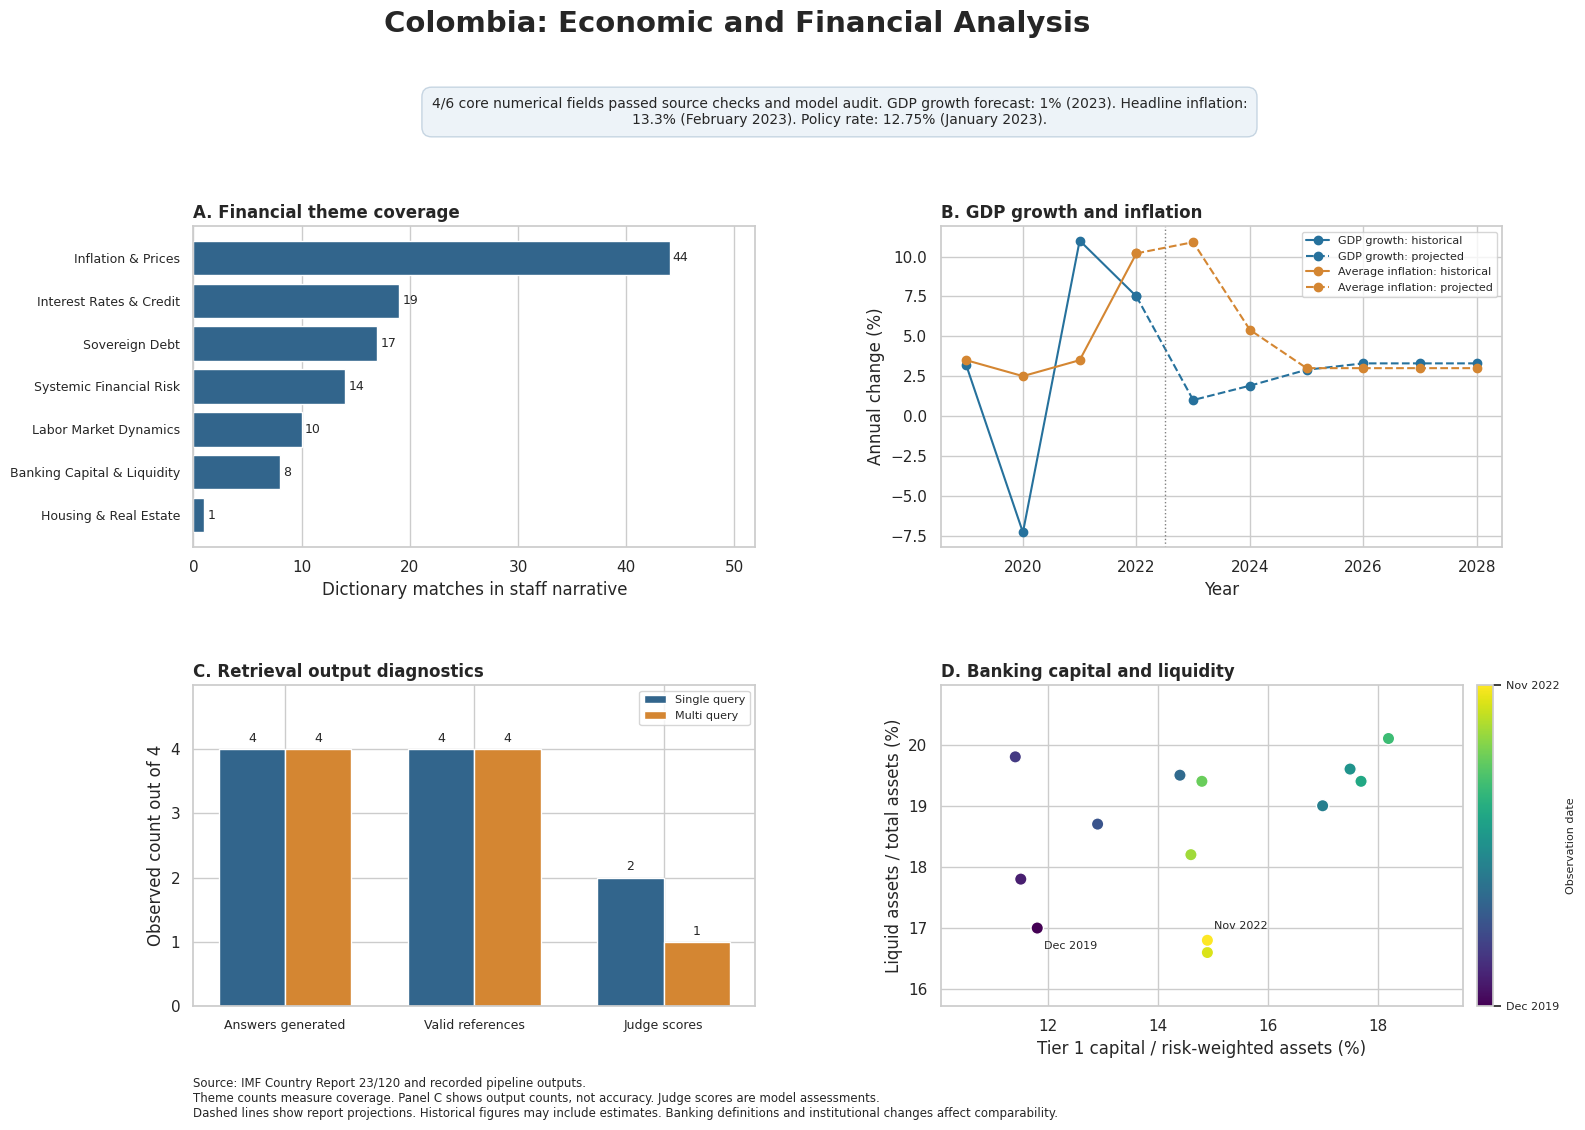

Populated panels: 4 / 4


In [18]:
%pip -q install matplotlib seaborn

import matplotlib.pyplot as plt
import seaborn as sns
import textwrap

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(2, 2, figsize=(17, 12))
fig.subplots_adjust(
    left=0.18, right=0.95,
    bottom=0.14, top=0.79,
    wspace=0.33, hspace=0.43,
)

country = core_indicators.get("country_name") or "Country report"

fig.suptitle(
    f"{country}: Economic and Financial Analysis",
    fontsize=21, fontweight="bold", y=0.97,
)

accepted_count = sum(
    core_indicators[field] is not None
    for field in indicator_specs
)

overlay_parts = [
    f"{accepted_count}/{len(indicator_specs)} core numerical fields "
    "passed source checks and model audit."
]

for field, label in {
    "gdp_growth_forecast_pct": "GDP growth forecast",
    "headline_inflation_rate_pct": "Headline inflation",
    "central_bank_policy_rate_pct": "Policy rate",
}.items():
    value = core_indicators[field]
    if value is not None:
        overlay_parts.append(
            f"{label}: {value:g}% "
            f"({indicator_records[field]['period']})."
        )

fig.text(
    0.56, 0.885,
    textwrap.fill(" ".join(overlay_parts), width=115),
    ha="center", va="center", fontsize=10,
    bbox={
        "boxstyle": "round,pad=0.7",
        "facecolor": "#edf3f8",
        "edgecolor": "#c6d5e2",
    },
)

plot_status = {}

# A. Theme counts
ax = axes[0, 0]
theme_frame = pd.DataFrame(theme_counts).sort_values("count")

ax.barh(
    theme_frame["theme"], theme_frame["count"],
    color="#32658c",
)
ax.set_title("A. Financial theme coverage", loc="left", fontweight="bold")
ax.set_xlabel("Dictionary matches in staff narrative")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=9)
ax.margins(x=0.18)

for index, count in enumerate(theme_frame["count"]):
    ax.text(count + 0.3, index, str(count), va="center", fontsize=9)

plot_status["themes"] = True

# B. Economic trends
ax = axes[0, 1]
ax.set_title("B. GDP growth and inflation", loc="left", fontweight="bold")

if not economic_wide.empty:
    historical = economic_wide[
        economic_wide["status"] != "Projection"
    ]
    projected = economic_wide[
        economic_wide["status"] == "Projection"
    ]

    for name, colour in {
        "GDP growth": "#26719c",
        "Average inflation": "#d48632",
    }.items():
        ax.plot(
            historical["year"], historical[name],
            marker="o", color=colour,
            label=f"{name}: historical",
        )

        if not projected.empty:
            bridge = pd.concat([historical.tail(1), projected])
            ax.plot(
                bridge["year"], bridge[name],
                marker="o", linestyle="--", color=colour,
                label=f"{name}: projected",
            )

    if not projected.empty:
        ax.axvline(
            projected["year"].min() - 0.5,
            color="gray", linestyle=":", linewidth=1,
        )

    ax.set_xlabel("Year")
    ax.set_ylabel("Annual change (%)")
    ax.legend(fontsize=8)
    plot_status["economic_trends"] = True
else:
    ax.text(
        0.5, 0.5, "Economic series unavailable",
        transform=ax.transAxes, ha="center",
    )
    plot_status["economic_trends"] = False

# C. Retrieval diagnostics
ax = axes[1, 0]
ax.set_title("C. Retrieval output diagnostics", loc="left", fontweight="bold")

diagnostic_columns = [
    "answer_generated", "references_valid", "score_available"
]
labels = ["Answers generated", "Valid references", "Judge scores"]
positions = np.arange(3)
width = 0.35

for offset, method, colour in [
    (-width / 2, "Single query", "#32658c"),
    (width / 2, "Multi query", "#d48632"),
]:
    values = rag_diagnostics.loc[
        method, diagnostic_columns
    ].to_numpy(dtype=float)

    bars = ax.bar(
        positions + offset, values,
        width=width, color=colour, label=method,
    )
    ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)

ax.set_xticks(positions, labels)
ax.set_ylabel(f"Observed count out of {len(rag_questions)}")
ax.set_ylim(0, len(rag_questions) + 1)
ax.set_yticks(range(len(rag_questions) + 1))
ax.tick_params(axis="x", labelsize=9)
ax.legend(fontsize=8)
plot_status["retrieval_diagnostics"] = True

# D. Banking observations
ax = axes[1, 1]
ax.set_title("D. Banking capital and liquidity", loc="left", fontweight="bold")

if not banking_wide.empty:
    bank = banking_wide.sort_values("date").reset_index(drop=True)
    dates = pd.to_datetime(bank["date"])
    date_values = dates.astype("int64").to_numpy() / 10**9

    points = ax.scatter(
        bank["Tier 1 capital ratio"],
        bank["Liquid assets ratio"],
        c=date_values, cmap="viridis",
        s=80, edgecolors="white",
    )

    for index, offset in [
        (0, (5, -15)),
        (len(bank) - 1, (5, 8)),
    ]:
        ax.annotate(
            dates.iloc[index].strftime("%b %Y"),
            (
                bank.iloc[index]["Tier 1 capital ratio"],
                bank.iloc[index]["Liquid assets ratio"],
            ),
            xytext=offset, textcoords="offset points", fontsize=8,
        )

    colourbar = fig.colorbar(
        points, ax=ax, pad=0.025, fraction=0.045
    )
    colourbar.set_ticks([date_values.min(), date_values.max()])
    colourbar.set_ticklabels([
        dates.iloc[0].strftime("%b %Y"),
        dates.iloc[-1].strftime("%b %Y"),
    ])
    colourbar.set_label("Observation date", fontsize=8)
    colourbar.ax.tick_params(labelsize=8)

    ax.set_xlabel("Tier 1 capital / risk-weighted assets (%)")
    ax.set_ylabel("Liquid assets / total assets (%)")
    ax.margins(x=0.20, y=0.25)
    plot_status["banking_scatter"] = True
else:
    ax.text(
        0.5, 0.5, "Banking series unavailable",
        transform=ax.transAxes, ha="center",
    )
    plot_status["banking_scatter"] = False

fig.text(
    0.18, 0.045,
    f"Source: IMF Country Report {document_info['report_number']} "
    "and recorded pipeline outputs.\n"
    "Theme counts measure coverage. Panel C shows output counts, not accuracy. "
    "Judge scores are model assessments.\n"
    "Dashed lines show report projections. Historical figures may include "
    "estimates. Banking definitions and institutional changes affect comparability.",
    fontsize=8.5, ha="left", va="bottom",
)

dashboard_path = OUTPUT_DIR / "colombia_article_iv_dashboard.png"
fig.savefig(dashboard_path, dpi=300, facecolor="white")
plt.show()
plt.close(fig)

save_json(OUTPUT_DIR / "dashboard_status.json", plot_status)

print("Populated panels:", sum(plot_status.values()), "/ 4")